# EuroSAT Land-Cover Classification — A Comparative Deep Learning Study with Transfer Learning

# Notebook 07 — Fine-Tuning


## 1. Objective

Notebooks 05 and 06 used **feature extraction**: an ImageNet-pretrained backbone stayed entirely frozen, and only a small new classification head was trained. This notebook takes the natural next step, **fine-tuning**: starting from that same frozen-backbone setup, a portion of the pretrained backbone is unfrozen and trained further, at a much smaller learning rate, so its features can adapt somewhat toward EuroSAT rather than staying exactly as ImageNet left them.

Two candidate architectures are fine-tuned here (selected and justified in Section 6, from the actual Notebook 06 results) — this notebook does not fine-tune all six architectures compared in Notebook 06, and it does not declare a final or best model for the project. The test set is not used anywhere below; it remains reserved for Notebook 08.

## 2. From Feature Extraction to Fine-Tuning

- **Feature Extraction** (Notebooks 05–06): `base_model.trainable = False`. Every pretrained weight is frozen; only the new head (`GlobalAveragePooling2D → Dropout(0.2) → Dense(10, softmax)`) is trained. This treats the pretrained backbone purely as a fixed feature extractor.
- **Fine-Tuning** (this notebook): the upper portion of the backbone is unfrozen and trained together with the head, at a learning rate roughly 100× smaller than the feature-extraction stage. The intuition: a pretrained CNN's early layers tend to encode generic, broadly-useful features (edges, textures, simple color/shape patterns), while its later layers encode more dataset-specific, abstract patterns learned from ImageNet specifically. Fine-tuning gives those later layers a chance to shift somewhat from "generic ImageNet" toward "EuroSAT-specific," while a small learning rate and a frozen lower portion limit how much the well-established generic features are disturbed.

No notebook in this project persists trained model weights to disk between notebooks (Notebook 06 retrained MobileNetV2 fresh rather than reusing Notebook 05's run, for the same reason). So for each candidate below, this notebook first repeats a short feature-extraction stage of its own — **Stage A** — to obtain a genuinely trained head before fine-tuning can meaningfully begin, then proceeds to **Stage B**, the actual fine-tuning stage. Only Stage B is "fine-tuning" in the sense this notebook is about; Stage A's own numbers are shown for transparency and as a reproducibility check against Notebook 06, but the **official Feature Extraction reference values used for comparison are Notebook 06's actual reported results**, not Stage A's re-run (see Section 13).

## 3. Imports and Configuration

In [1]:
from pathlib import Path
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split

In [ ]:
DATASET_ROOT = Path("data/EuroSAT_RGB")

CLASS_NAMES = [
    "AnnualCrop", "Forest", "HerbaceousVegetation",
    "Highway", "Industrial", "Pasture",
    "PermanentCrop", "Residential", "River",
    "SeaLake",
]

CLASS_TO_ID = {class_name: idx for idx, class_name in enumerate(CLASS_NAMES)}
EXPECTED_EXTENSIONS = {".jpg", ".jpeg"}

SEED = 42
IMAGE_SIZE = (128, 128)   # same input size used throughout Notebooks 05-06
IMG_SHAPE = IMAGE_SIZE + (3,)
NUM_CLASSES = 10
BATCH_SIZE = 32

EPOCHS = 15                    # same epoch ceiling used in every previous notebook
                                # for both Stage A and Stage B below; EarlyStopping
                                # (patience=5) decides the actual stopping point either way
LR_FEATURE_EXTRACTION = 1e-3   # same as Notebooks 05-06, for Stage A
LR_FINE_TUNE = 1e-5            # ~100x smaller than the feature-extraction LR (Section 7)
UNFREEZE_FRACTION = 0.20       # unfreeze the top 20% of backbone layers (Section 7)


def set_seeds(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)


set_seeds(SEED)

## 4. Dataset and Stratified Split

Standalone, exactly as in Notebooks 02, 05, and 06: the manifest and the same two-stage stratified 80/10/10 split (`SEED = 42`) are recreated identically. `test_df` is recreated only for the split arithmetic — **no `test_ds` is built or used anywhere in this notebook.**

In [3]:
records = []
for class_name in CLASS_NAMES:
    class_dir = DATASET_ROOT / class_name
    for path in class_dir.iterdir():
        if path.is_file() and path.suffix.lower() in EXPECTED_EXTENSIONS:
            records.append((str(path), class_name, CLASS_TO_ID[class_name]))

manifest_df = pd.DataFrame(records, columns=["filepath", "class_name", "label"])

train_df, temp_df = train_test_split(
    manifest_df, test_size=0.20, stratify=manifest_df["label"], random_state=SEED,
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED,
)
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

print(f"Train:      {len(train_df)}")
print(f"Validation: {len(val_df)}")
print(f"(Test set:  {len(test_df)} — not loaded into a tf.data.Dataset in this notebook)")

Train:      21600
Validation: 2700
(Test set:  2700 — not loaded into a tf.data.Dataset in this notebook)


## 5. TensorFlow Input Pipeline

Same pattern as Notebook 06: `build_datasets` takes a `preprocess_fn` so each architecture gets its own correct preprocessing (Section 6), applied exactly once to raw resized pixels — never divided by 255 first.

In [4]:
def build_datasets(preprocess_fn):
    def load_image(filepath, label):
        image = tf.io.read_file(filepath)
        image = tf.image.decode_jpeg(image, channels=3)
        image = tf.image.resize(image, IMAGE_SIZE)
        image = tf.cast(image, tf.float32)
        image = preprocess_fn(image)
        return image, label

    def make_dataset(df, shuffle):
        filepaths = df["filepath"].values
        labels = df["label"].values
        ds = tf.data.Dataset.from_tensor_slices((filepaths, labels))
        if shuffle:
            ds = ds.shuffle(buffer_size=len(df), seed=SEED, reshuffle_each_iteration=True)
        ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
        ds = ds.batch(BATCH_SIZE)
        ds = ds.prefetch(tf.data.AUTOTUNE)
        return ds

    return make_dataset(train_df, shuffle=True), make_dataset(val_df, shuffle=False)

## 6. Candidate Model Selection

Notebook 06's frozen-feature-extraction results:

| Architecture | Val Accuracy | Val Loss | Total Params | Training Time |
|---|---:|---:|---:|---:|
| ResNet50 | 95.70% | 0.1567 | 23,608,202 | ~1h 23m |
| EfficientNetB0 | 95.26% | 0.1408 | 4,062,381 | ~1h 1m |
| DenseNet121 | 95.15% | 0.1444 | 7,047,754 | ~2h 47m |
| MobileNetV2 | 93.70% | 0.1814 | 2,270,794 | ~24m |
| VGG16 | 92.15% | 0.2390 | 14,719,818 | ~3h 42m |
| InceptionV3 | 86.07% | 0.4882 | 21,823,274 | ~23m |

**Selected for fine-tuning: ResNet50 and EfficientNetB0.**

- They were the two strongest performers on validation accuracy in Notebook 06 (95.70% and 95.26%), making them the most natural candidates to push further — fine-tuning a clearly weaker architecture first would be a less informative use of the additional training time fine-tuning requires.
- Between the top three (ResNet50, EfficientNetB0, DenseNet121, all within 0.55 points of each other on accuracy), **DenseNet121 is deliberately excluded**: it took roughly 2h 47m for feature extraction alone in Notebook 06 — over twice ResNet50's time and nearly three times EfficientNetB0's — for essentially the same accuracy. Fine-tuning (Stage A + Stage B, Section 2) would multiply that cost further, which is a disproportionate time cost for a result this project's other two candidates already cover.
- **MobileNetV2** is a reasonable candidate for a *cost-conscious* fine-tuning story (it was by far the fastest architecture in Notebook 06), but at 93.70% it was clearly behind the top three on accuracy; it is left out here to keep this notebook focused on two candidates rather than three.
- **VGG16 and InceptionV3** are excluded: VGG16 was both the slowest of the six architectures and behind on accuracy, and InceptionV3 was the one architecture that underperformed the Notebook 03 scratch baseline in Notebook 06 — neither is a strong candidate for the additional investment fine-tuning requires.

This is a two-model comparison, not an attempt to fine-tune every Notebook 06 architecture.

## 7. Fine-Tuning Helper

`feature_extract_and_fine_tune` runs both stages for one architecture:

**Stage A (feature extraction):** identical in spirit to Notebook 06 — frozen backbone, `GlobalAveragePooling2D → Dropout(0.2) → Dense(10, softmax)` head, `base_model(inputs, training=False)` to keep the backbone's BatchNormalization layers in inference mode, Adam at `LR_FEATURE_EXTRACTION`.

**Stage B (fine-tuning):** the *same* model object continues from Stage A's trained weights (not reinitialized). `base_model.trainable = True`, then the bottom `1 - UNFREEZE_FRACTION` (80%) of the backbone's layers are explicitly re-frozen, leaving only the top 20% trainable — except any `BatchNormalization` layer, which is **kept frozen even within that unfrozen top portion**. This is deliberate: `base_model(inputs, training=False)` already keeps BatchNorm layers using their pretrained running statistics rather than batch statistics during every call in this notebook (both stages), but explicitly setting `layer.trainable = False` on every BatchNormalization layer is kept as a second, explicit safeguard — so their pretrained statistics can't be disturbed even if this code is later reused somewhere that calls the model with `training=True`. The model is then recompiled (required whenever trainable weights change) with the much smaller `LR_FINE_TUNE`, and training continues with the same `EarlyStopping` configuration used throughout this project.

No `ModelCheckpoint` is used — `EarlyStopping(restore_best_weights=True)` already restores the best-validation-loss weights, consistent with every previous notebook in this project, none of which persists model files to disk either.

In [ ]:
results = []

def feature_extract_and_fine_tune(name, base_model_fn, preprocess_fn):
    set_seeds()
    train_ds, val_ds = build_datasets(preprocess_fn)

    #  Stage A: Feature Extraction (frozen backbone) 
    base_model = base_model_fn(input_shape=IMG_SHAPE, include_top=False, weights="imagenet")
    base_model.trainable = False

    inputs = tf.keras.Input(shape=IMG_SHAPE)
    x = base_model(inputs, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(0.2)(x)
    outputs = tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")(x)
    model = tf.keras.Model(inputs, outputs, name=f"{name}_finetune")

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LR_FEATURE_EXTRACTION),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )

    fe_early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=5, restore_best_weights=True,
    )

    fe_start = time.time()
    fe_history = model.fit(
        train_ds, validation_data=val_ds, epochs=EPOCHS,
        callbacks=[fe_early_stopping], shuffle=False, verbose=2,
    )
    fe_time_s = round(time.time() - fe_start, 1)

    fe_history_df = pd.DataFrame(fe_history.history)
    fe_history_df.index = fe_history_df.index + 1
    fe_history_df.index.name = "epoch"

    fe_best_val_acc = float(fe_history_df["val_accuracy"].max())
    fe_best_val_acc_epoch = int(fe_history_df["val_accuracy"].idxmax())
    fe_best_val_loss = float(fe_history_df["val_loss"].min())
    fe_best_val_loss_epoch = int(fe_history_df["val_loss"].idxmin())

    print(f"[{name}] Stage A (this notebook's own feature-extraction run — for "
          f"reference/reproducibility only; Section 13 uses Notebook 06's actual "
          f"reported values, not this number):")
    print(f"  best val_accuracy={fe_best_val_acc:.2%} (epoch {fe_best_val_acc_epoch}), "
          f"best val_loss={fe_best_val_loss:.4f} (epoch {fe_best_val_loss_epoch}), "
          f"time={fe_time_s}s")

    #  Stage B: Fine-Tuning (unfreeze top UNFREEZE_FRACTION of the backbone) 
    base_model.trainable = True
    freeze_until = int(len(base_model.layers) * (1 - UNFREEZE_FRACTION))
    for i, layer in enumerate(base_model.layers):
        if i < freeze_until:
            layer.trainable = False
        else:
            # Keep BatchNormalization layers frozen even in the unfrozen upper portion
            # (Section 7) --> protects their pretrained running statistics
            layer.trainable = not isinstance(layer, tf.keras.layers.BatchNormalization)

    n_unfrozen_layers = sum(1 for layer in base_model.layers if layer.trainable)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LR_FINE_TUNE),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )

    ft_early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=5, restore_best_weights=True,
    )

    ft_start = time.time()
    ft_history = model.fit(
        train_ds, validation_data=val_ds, epochs=EPOCHS,
        callbacks=[ft_early_stopping], shuffle=False, verbose=2,
    )
    ft_time_s = round(time.time() - ft_start, 1)

    ft_history_df = pd.DataFrame(ft_history.history)
    ft_history_df.index = ft_history_df.index + 1
    ft_history_df.index.name = "epoch"

    ft_best_val_acc = float(ft_history_df["val_accuracy"].max())
    ft_best_val_acc_epoch = int(ft_history_df["val_accuracy"].idxmax())
    ft_best_val_loss = float(ft_history_df["val_loss"].min())
    ft_best_val_loss_epoch = int(ft_history_df["val_loss"].idxmin())

    total_params = model.count_params()
    trainable_params = sum(int(tf.size(w)) for w in model.trainable_weights)
    non_trainable_params = sum(int(tf.size(w)) for w in model.non_trainable_weights)

    print(f"[{name}] Stage B (fine-tuning, {n_unfrozen_layers} unfrozen backbone layers, "
          f"lr={LR_FINE_TUNE}):")
    print(f"  best val_accuracy={ft_best_val_acc:.2%} (epoch {ft_best_val_acc_epoch}), "
          f"best val_loss={ft_best_val_loss:.4f} (epoch {ft_best_val_loss_epoch}), "
          f"trainable={trainable_params:,}/{total_params:,}, time={ft_time_s}s")
    print(f"  Total time (Stage A + Stage B): {round(fe_time_s + ft_time_s, 1)}s")

    results.append({
        "Model": name,
        "FE Val Accuracy (This Notebook)": fe_best_val_acc,
        "FT Val Accuracy": ft_best_val_acc,
        "FE Val Loss (This Notebook)": fe_best_val_loss,
        "FT Val Loss": ft_best_val_loss,
        "Best FT Accuracy Epoch": ft_best_val_acc_epoch,
        "Best FT Loss Epoch": ft_best_val_loss_epoch,
        "Total Parameters": total_params,
        "Trainable Parameters (Fine-Tuning)": trainable_params,
        "Unfrozen Backbone Layers": n_unfrozen_layers,
        "Fine-Tuning Learning Rate": LR_FINE_TUNE,
        "FT Training Time (s)": ft_time_s,
        "Total Training Time (s)": round(fe_time_s + ft_time_s, 1),
    })

    return fe_history_df, ft_history_df

## 8. Fine-Tuning Model 1 — ResNet50

ResNet50 had the highest Notebook 06 feature-extraction accuracy (95.70%). Its residual connections are specifically designed to keep deep networks trainable, which is a reasonable property to carry into fine-tuning as well, where gradients now also need to propagate usefully through the newly-unfrozen upper layers.

In [6]:
fe_hist_resnet, ft_hist_resnet = feature_extract_and_fine_tune(
    "resnet50",
    tf.keras.applications.ResNet50,
    tf.keras.applications.resnet50.preprocess_input,
)

Epoch 1/15
675/675 - 312s - 462ms/step - accuracy: 0.8947 - loss: 0.3334 - val_accuracy: 0.9433 - val_loss: 0.1753
Epoch 2/15
675/675 - 416s - 616ms/step - accuracy: 0.9438 - loss: 0.1691 - val_accuracy: 0.9441 - val_loss: 0.1778
Epoch 3/15
675/675 - 585s - 866ms/step - accuracy: 0.9535 - loss: 0.1391 - val_accuracy: 0.9456 - val_loss: 0.1584
Epoch 4/15
675/675 - 625s - 926ms/step - accuracy: 0.9612 - loss: 0.1178 - val_accuracy: 0.9470 - val_loss: 0.1606
Epoch 5/15
675/675 - 591s - 876ms/step - accuracy: 0.9629 - loss: 0.1056 - val_accuracy: 0.9515 - val_loss: 0.1632
Epoch 6/15
675/675 - 606s - 898ms/step - accuracy: 0.9658 - loss: 0.0981 - val_accuracy: 0.9485 - val_loss: 0.1612
Epoch 7/15
675/675 - 595s - 882ms/step - accuracy: 0.9681 - loss: 0.0944 - val_accuracy: 0.9519 - val_loss: 0.1567
Epoch 8/15
675/675 - 582s - 863ms/step - accuracy: 0.9706 - loss: 0.0843 - val_accuracy: 0.9570 - val_loss: 0.1589
Epoch 9/15
675/675 - 547s - 810ms/step - accuracy: 0.9723 - loss: 0.0775 - val_a

## 9. Fine-Tuning Model 2 — EfficientNetB0

EfficientNetB0 had the lowest Notebook 06 validation loss (0.1408) and the second-highest accuracy (95.26%), at roughly one sixth of ResNet50's parameter count — a useful contrast to ResNet50: does fine-tuning affect a much smaller, differently-designed (compound-scaled) architecture the same way?

In [7]:
fe_hist_efficientnet, ft_hist_efficientnet = feature_extract_and_fine_tune(
    "efficientnetb0",
    tf.keras.applications.EfficientNetB0,
    tf.keras.applications.efficientnet.preprocess_input,
)

Epoch 1/15
675/675 - 250s - 370ms/step - accuracy: 0.8693 - loss: 0.4555 - val_accuracy: 0.9226 - val_loss: 0.2464
Epoch 2/15
675/675 - 207s - 306ms/step - accuracy: 0.9237 - loss: 0.2391 - val_accuracy: 0.9363 - val_loss: 0.1989
Epoch 3/15
675/675 - 257s - 380ms/step - accuracy: 0.9347 - loss: 0.2037 - val_accuracy: 0.9393 - val_loss: 0.1760
Epoch 4/15
675/675 - 258s - 383ms/step - accuracy: 0.9389 - loss: 0.1860 - val_accuracy: 0.9422 - val_loss: 0.1715
Epoch 5/15
675/675 - 269s - 399ms/step - accuracy: 0.9425 - loss: 0.1759 - val_accuracy: 0.9419 - val_loss: 0.1629
Epoch 6/15
675/675 - 255s - 378ms/step - accuracy: 0.9456 - loss: 0.1672 - val_accuracy: 0.9437 - val_loss: 0.1548
Epoch 7/15
675/675 - 256s - 379ms/step - accuracy: 0.9461 - loss: 0.1622 - val_accuracy: 0.9404 - val_loss: 0.1590
Epoch 8/15
675/675 - 268s - 397ms/step - accuracy: 0.9479 - loss: 0.1533 - val_accuracy: 0.9456 - val_loss: 0.1530
Epoch 9/15
675/675 - 254s - 377ms/step - accuracy: 0.9473 - loss: 0.1521 - val_a

## 10. Training History Visualization

For each candidate, one accuracy plot and one loss plot, with Stage A (feature extraction) epochs followed by Stage B (fine-tuning) epochs on a continuous axis, and a vertical dashed line marking where fine-tuning begins — useful for seeing whether validation performance actually improves once the backbone starts adapting, or whether it destabilizes.

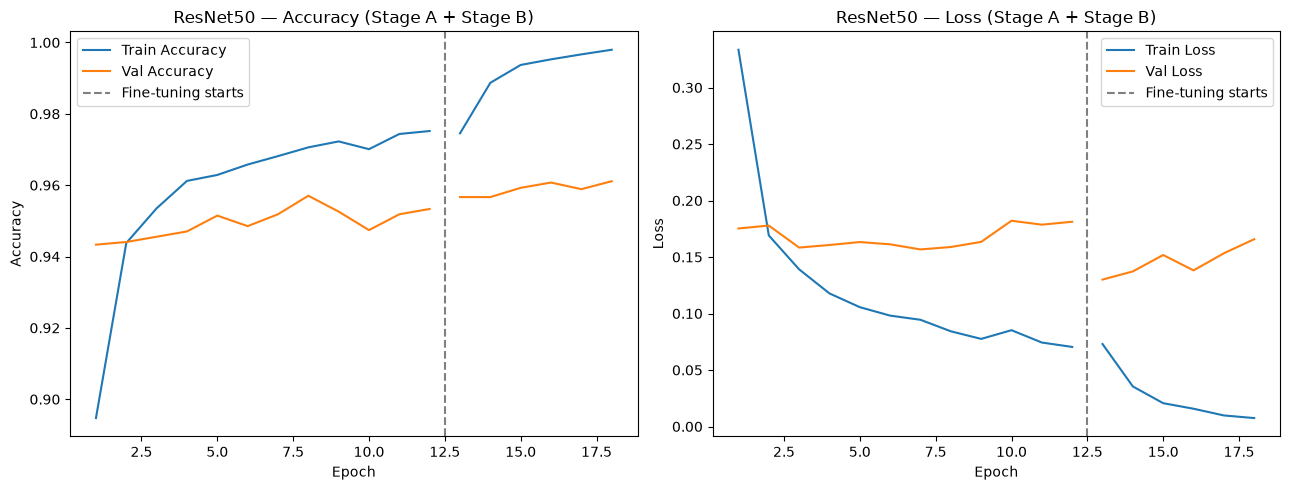

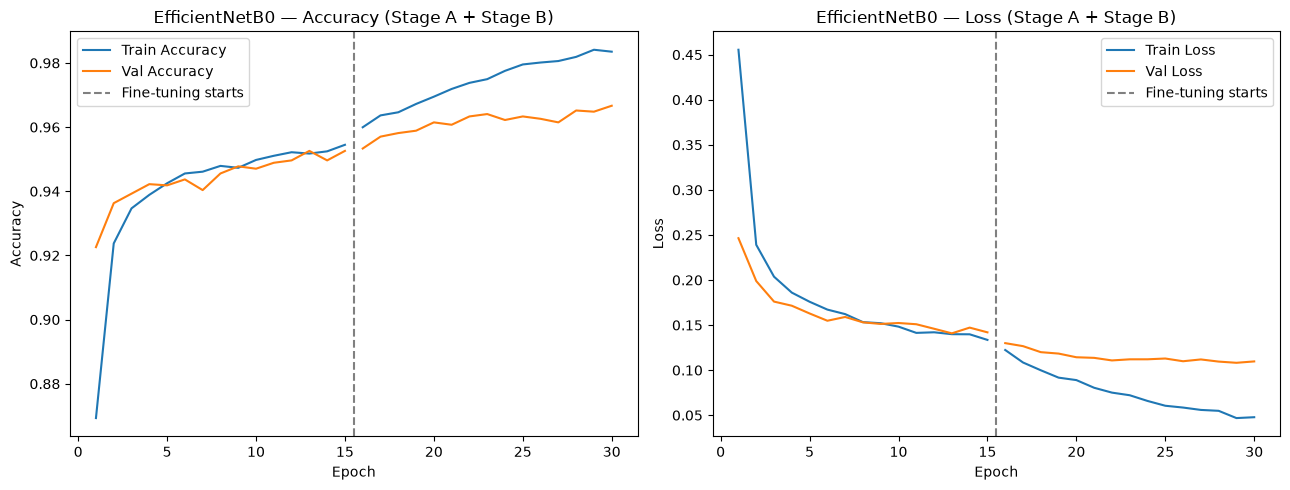

In [8]:
def plot_fe_ft_curves(name, fe_hist, ft_hist):
    ft_hist_shifted = ft_hist.copy()
    ft_hist_shifted.index = ft_hist_shifted.index + fe_hist.index.max()
    fine_tune_start = fe_hist.index.max() + 0.5

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    axes[0].plot(fe_hist.index, fe_hist["accuracy"], label="Train Accuracy", color="tab:blue")
    axes[0].plot(fe_hist.index, fe_hist["val_accuracy"], label="Val Accuracy", color="tab:orange")
    axes[0].plot(ft_hist_shifted.index, ft_hist_shifted["accuracy"], color="tab:blue")
    axes[0].plot(ft_hist_shifted.index, ft_hist_shifted["val_accuracy"], color="tab:orange")
    axes[0].axvline(fine_tune_start, color="gray", linestyle="--", label="Fine-tuning starts")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Accuracy")
    axes[0].set_title(f"{name} — Accuracy (Stage A + Stage B)")
    axes[0].legend()

    axes[1].plot(fe_hist.index, fe_hist["loss"], label="Train Loss", color="tab:blue")
    axes[1].plot(fe_hist.index, fe_hist["val_loss"], label="Val Loss", color="tab:orange")
    axes[1].plot(ft_hist_shifted.index, ft_hist_shifted["loss"], color="tab:blue")
    axes[1].plot(ft_hist_shifted.index, ft_hist_shifted["val_loss"], color="tab:orange")
    axes[1].axvline(fine_tune_start, color="gray", linestyle="--", label="Fine-tuning starts")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Loss")
    axes[1].set_title(f"{name} — Loss (Stage A + Stage B)")
    axes[1].legend()

    plt.tight_layout()
    plt.show()


plot_fe_ft_curves("ResNet50", fe_hist_resnet, ft_hist_resnet)
plot_fe_ft_curves("EfficientNetB0", fe_hist_efficientnet, ft_hist_efficientnet)

## 11. Results Summary

In [9]:
results_df = pd.DataFrame(results)

display_df = results_df.copy()
for col in ["FE Val Accuracy (This Notebook)", "FT Val Accuracy"]:
    display_df[col] = display_df[col].map(lambda v: f"{v:.2%}")
for col in ["FE Val Loss (This Notebook)", "FT Val Loss"]:
    display_df[col] = display_df[col].map(lambda v: f"{v:.4f}")

display_df

,Model,FE Val Accuracy (This Notebook),FT Val Accuracy,FE Val Loss (This Notebook),FT Val Loss,Best FT Accuracy Epoch,Best FT Loss Epoch,Total Parameters,Trainable Parameters (Fine-Tuning),Unfrozen Backbone Layers,Fine-Tuning Learning Rate,FT Training Time (s),Total Training Time (s)
0,resnet50,95.70%,96.11%,0.1567,0.1300,6,1,23608202,14973962,24,0.00001,4630.9,11031.2
1,efficientnetb0,95.26%,96.67%,0.1408,0.1081,15,14,4062381,2300314,38,0.00001,6363.0,10165.0


## 12. Feature Extraction vs. Fine-Tuning Comparison

The **Feature Extraction** columns below use Notebook 06's actual reported results (not Stage A's re-run above) as the official reference point, per this project's convention of not re-deriving numbers that an earlier notebook already established.

The fine-tuning accuracy column is the peak validation accuracy across Stage B epochs, and the fine-tuning loss column is the minimum validation loss. The two can occur at different epochs, so the table's **Best Val-Loss Epoch** column states explicitly that it is the Stage B epoch with the lowest validation loss (the epoch `EarlyStopping` monitors on `val_loss`). Peak accuracy occurred at Epoch 6 for ResNet50 and Epoch 15 for EfficientNetB0.

In [10]:
feature_extraction_reference = {
    "resnet50": {"Val Accuracy": 0.9570, "Val Loss": 0.1567},
    "efficientnetb0": {"Val Accuracy": 0.9526, "Val Loss": 0.1408},
}

comparison_rows = []
for row in results:
    key = row["Model"]
    ref = feature_extraction_reference[key]
    comparison_rows.append({
        "Model": key,
        "Feature Extraction Val Accuracy": ref["Val Accuracy"],
        "Fine-Tuning Val Accuracy": row["FT Val Accuracy"],
        "Feature Extraction Val Loss": ref["Val Loss"],
        "Fine-Tuning Val Loss": row["FT Val Loss"],
        "Best Val-Loss Epoch": row["Best FT Loss Epoch"],
        "Trainable Parameters": row["Trainable Parameters (Fine-Tuning)"],
        "Training Time (s)": row["FT Training Time (s)"],
    })

comparison_df = pd.DataFrame(comparison_rows)

comparison_display_df = comparison_df.copy()
for col in ["Feature Extraction Val Accuracy", "Fine-Tuning Val Accuracy"]:
    comparison_display_df[col] = comparison_display_df[col].map(lambda v: f"{v:.2%}")
for col in ["Feature Extraction Val Loss", "Fine-Tuning Val Loss"]:
    comparison_display_df[col] = comparison_display_df[col].map(lambda v: f"{v:.4f}")

comparison_display_df

,Model,Feature Extraction Val Accuracy,Fine-Tuning Val Accuracy,Feature Extraction Val Loss,Fine-Tuning Val Loss,Best Val-Loss Epoch,Trainable Parameters,Training Time (s)
0,resnet50,95.70%,96.11%,0.1567,0.1300,1,14973962,4630.9
1,efficientnetb0,95.26%,96.67%,0.1408,0.1081,14,2300314,6363.0


**Interpretation (this experiment only):**

- **ResNet50.** Compared with Notebook 06's frozen result (95.70% / 0.1567), Stage B reached a peak validation accuracy of 96.11% (+0.41 points, Epoch 6) and a minimum validation loss of 0.1300 (−0.0267, Epoch 1). The two best values come from different epochs. At Epoch 1 of Stage B, where the loss was lowest, validation accuracy was 95.67%, slightly below the frozen 95.70%. `EarlyStopping` stopped the run at Epoch 6 and restored the best-loss (Epoch 1) weights, so the 96.11% accuracy is a peak-epoch value that does not belong to the restored weights.
- **EfficientNetB0.** Compared with Notebook 06's frozen result (95.26% / 0.1408), Stage B reached a peak validation accuracy of 96.67% (+1.41 points, Epoch 15) and a minimum validation loss of 0.1081 (−0.0327, Epoch 14). These two epochs are adjacent. Epoch 14 had 96.48% validation accuracy and Epoch 15 had 96.67% accuracy with a validation loss of 0.1097. Because `restore_best_weights=True` follows `val_loss`, the epoch with the lowest validation loss (14), not the peak-accuracy epoch (15), is the relevant best epoch for this model; Notebook 08 includes a validation-only check of the model state it evaluates.
- **Overall.** In this setup, fine-tuning improved both the peak validation accuracy and the minimum validation loss relative to Notebook 06 for both models, and the improvement was larger for EfficientNetB0 than for ResNet50. The accuracy difference between the two fine-tuned models is 0.56 points (about 15 of the 2,700 validation images). These are single runs on validation data, so the results describe this configuration and are not a claim that fine-tuning always helps.


## 13. Overfitting Analysis

Based on the plots in Section 10 and the numbers in Sections 11–12. **Observation**, **Possible explanation**, and **Confirmed conclusion** are kept separate — a possible explanation is not a confirmed cause.

**For ResNet50:**
- *Observation:* Over the 6 epochs of Stage B, training accuracy rose from 97.45% to 99.80% and training loss fell from 0.0730 to 0.0075. Validation loss was lowest in the first epoch (0.1300) and was higher in every later epoch (0.1373, 0.1518, 0.1382, 0.1533, 0.1658), while validation accuracy ranged from 95.67% to 96.11% (peak at Epoch 6). By Epoch 6 the gap between training and validation accuracy was 3.69 points (99.80% vs 96.11%).
- *Possible explanation:* With 24 backbone layers unfrozen (14,973,962 of 23,608,202 parameters, about 63%), the network may fit the training set quickly, so that after the first epoch further training mainly improves training metrics rather than validation loss — a pattern consistent with overfitting. Whether a smaller unfreeze fraction or a different learning rate would behave differently was not tested.
- *Confirmed conclusion:* Validation loss reached its minimum (0.1300) at Stage B Epoch 1 and did not improve afterward, while training loss kept falling. The underlying mechanism was not isolated.

**For EfficientNetB0:**
- *Observation:* Over 15 epochs of Stage B, training accuracy rose from 96.00% to 98.35% and training loss fell from 0.1223 to 0.0478, while validation loss fell from 0.1300 at Epoch 1 to 0.1081 at Epoch 14, with small fluctuations (for example 0.1099 at Epoch 11, then 0.1119 at Epoch 12, and 0.1097 at Epoch 15), and validation accuracy rose from 95.33% to 96.67% (Epoch 15). The gap between training and validation accuracy at Epoch 15 was 1.68 points (98.35% vs 96.67%).
- *Possible explanation:* With 38 layers unfrozen (2,300,314 of 4,062,381 parameters, about 57%) in a smaller model, adaptation at the same learning rate may have been more gradual. This was not tested.
- *Confirmed conclusion:* Validation loss was still near its best at the end of the run (best at Epoch 14, one epoch before the 15-epoch limit), and the validation accuracy peak was at Epoch 15. This run therefore does not show whether more epochs would have improved the model further or started to overfit it.

**Did EarlyStopping trigger?** For ResNet50, yes: it stopped after Stage B Epoch 6 (best-loss Epoch 1 + patience 5) and restored the Epoch 1 weights. For EfficientNetB0, no: the run reached the 15-epoch limit (best-loss Epoch 14, so only one epoch of patience had elapsed).

EfficientNetB0 showed more sustained validation improvement during this fine-tuning run, whereas ResNet50's validation loss was best in the first epoch and did not improve afterward. This describes these two runs only; it is not a statement about the two architectures in general.


## 14. Key Observations

1. **Fine-tuning vs frozen features.** For both candidates, Stage B improved on Notebook 06's frozen-feature results in peak validation accuracy and minimum validation loss: ResNet50 from 95.70% / 0.1567 to 96.11% / 0.1300, and EfficientNetB0 from 95.26% / 0.1408 to 96.67% / 0.1081. For ResNet50 the best accuracy (Epoch 6) and best loss (Epoch 1) come from different epochs, and the restored weights are the Epoch 1 ones, where validation accuracy was 95.67%.
2. **The two candidates compared.** EfficientNetB0 had the higher peak validation accuracy (96.67% vs 96.11%, a 0.56-point difference, about 15 validation images) and the lower minimum validation loss (0.1081 vs 0.1300). EfficientNetB0 showed more sustained validation improvement during the fine-tuning run; ResNet50's validation loss was best in the first epoch and then rose. These are single runs under one configuration.
3. **Trainable parameters.** ResNet50 trained 14,973,962 of 23,608,202 parameters (about 63%, with 24 unfrozen backbone layers); EfficientNetB0 trained 2,300,314 of 4,062,381 (about 57%, with 38 unfrozen layers). Unfreezing the top 20% of layers corresponds to more than 20% of the parameters because the upper layers are larger.
4. **Training time.** Stage B took 4,630.9 s for ResNet50 (6 epochs, about 772 s per epoch) and 6,363.0 s for EfficientNetB0 (15 epochs, about 424 s per epoch). Notebook 06's frozen runs took 5,008.6 s (12 epochs, about 417 s per epoch) and 3,671.6 s (15 epochs, about 245 s per epoch), so a fine-tuning epoch cost about 1.7–1.9 times a frozen epoch for these models. Including Stage A, the totals were 11,031.2 s (ResNet50) and 10,165.0 s (EfficientNetB0). The same frozen runs repeated as Stage A took 6,400.3 s and 3,802.0 s, so timings vary between runs.
5. **Reproducibility of Stage A.** Stage A reproduced Notebook 06's validation results for both models (ResNet50: 95.70% / 0.1567; EfficientNetB0: 95.26% / 0.1408, with the same best epochs).
6. **EarlyStopping.** It triggered for ResNet50 (stopped at Stage B Epoch 6) and did not for EfficientNetB0, which reached the 15-epoch limit.
7. **Possible follow-up.** The ResNet50 overfitting pattern suggests it might respond differently to a smaller unfreeze fraction or a lower learning rate, and EfficientNetB0's run does not show where its validation performance would level off. Neither was tested, to avoid hyperparameter tuning in this project.
8. The test set was not used.


## 15. Limitations

- Only two of Notebook 06's six architectures were fine-tuned (Section 6); this says nothing about how the other four would respond to fine-tuning.
- The unfreeze fraction (20%) and fine-tuning learning rate (1e-5) were each chosen once, with the reasoning given in Section 7 — neither was tuned or searched over, so a different choice for either could plausibly change the results.
- As in Notebook 06, 128×128 input resolution was used rather than each architecture's native 224×224 — this may still be limiting fine-tuning's ability to adapt features that were originally learned at a different scale.
- Each model was fine-tuned in a single run; Notebook 04 already showed that CNN training on this dataset can vary noticeably between runs, so close results should be read with that in mind.
- Stage A (this notebook's own feature-extraction warm-up) is not the same run as Notebook 06's — it uses identical configuration, but is a separate execution, not a guarantee of an identical result (Notebook 06 itself showed this: MobileNetV2 happened to reproduce Notebook 05's numbers exactly, but that is not guaranteed in general).
- All results are validation-only; the test set was not used anywhere in this notebook and remains reserved for Notebook 08.
- These results do not establish a final or best model for the project — Notebook 08 is where the test set is finally used, on whichever model(s) are carried forward.

## 16. Conclusion

This notebook took the two strongest architectures from Notebook 06's frozen-feature-extraction comparison, ResNet50 and EfficientNetB0, and fine-tuned each by unfreezing the top 20% of its backbone (excluding BatchNormalization layers) and continuing training at a much smaller learning rate (1e-5) than the feature-extraction stage.

In this setup, fine-tuning improved the peak validation accuracy and the minimum validation loss for both models relative to Notebook 06's frozen-feature results. ResNet50 went from 95.70% / 0.1567 to a peak accuracy of 96.11% (Epoch 6) and a minimum loss of 0.1300 (Epoch 1), with `EarlyStopping` triggering after Epoch 6. EfficientNetB0 went from 95.26% / 0.1408 to a peak accuracy of 96.67% (Epoch 15) and a minimum loss of 0.1081 (Epoch 14), reaching the 15-epoch limit without `EarlyStopping`. EfficientNetB0 benefited more in this run and showed more sustained validation improvement during fine-tuning, while ResNet50's validation loss was best in its first fine-tuning epoch. These are single-run, validation-only results for one fine-tuning configuration (top 20% of layers, learning rate 1e-5), so they do not show that either architecture is better in general. No model is declared the project's final or best model here, and the test set was not used for this comparison.


## 17. What Comes Next

Notebook 08 — Final Evaluation & Error Analysis — is the final notebook in this project, and the first (and only) one where the test set is used: whichever model(s) look strongest across Notebooks 03–07 will be evaluated once on the held-out 2,700-image test set, followed by a confusion matrix and error analysis that bring the project's results together into a final conclusion.